In [15]:
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score, recall_score, f1_score

import matplotlib.pyplot as plt
import seaborn as sns
import shap
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve

## 1. Загружаем данные
Делим их на данные для обучения и теcта, выделяем категориальные фичи, указываем параметр `stratify=y`, гарантирующий, что в обучающей выборке число классов `loan_status` будет одинаковым

In [4]:
df = pd.read_csv('../data/feautred.csv')
X = df.drop('loan_status', axis=1)
y = df['loan_status']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
cat_feautres = ['business_type', 'is_rev_line_of_loan', 'is_franchise', 'industry_sector', 'okved_risk_level', 'has_tax_arrears', 'has_blocked_accounts', 'loan_purpose', 'ownership_structure', 'business_scale']

## 2. Создаем и обучаем модель

In [ ]:
model = CatBoostClassifier(
    iterations=2000,
    learning_rate=0.05,
    depth=6,
    loss_function='Logloss',
    eval_metric='Logloss',
    auto_class_weights='Balanced',
    task_type='GPU',
    random_seed=42,
    verbose=100
)

In [6]:
model.fit(
    X_train, y_train,
    cat_features=cat_feautres,
    eval_set=(X_test, y_test),
    early_stopping_rounds=100,
    use_best_model=True
)

0:	learn: 0.6880373	test: 0.6880531	best: 0.6880531 (0)	total: 125ms	remaining: 4m 9s
100:	learn: 0.6375714	test: 0.6383958	best: 0.6383958 (100)	total: 10.8s	remaining: 3m 23s
200:	learn: 0.6366149	test: 0.6379246	best: 0.6379241 (198)	total: 21s	remaining: 3m 7s
300:	learn: 0.6360363	test: 0.6378442	best: 0.6378433 (299)	total: 31.4s	remaining: 2m 57s
400:	learn: 0.6354095	test: 0.6378045	best: 0.6378045 (400)	total: 41.7s	remaining: 2m 46s
500:	learn: 0.6348569	test: 0.6377671	best: 0.6377641 (474)	total: 51.9s	remaining: 2m 35s
bestTest = 0.637764063
bestIteration = 474
Shrink model to first 475 iterations.


CatBoostClassifier(auto_class_weights='Balanced', depth=6, eval_metric='Logloss', iterations=2000, learning_rate=0.05, loss_function='Logloss', random_seed=42, task_type='GPU', verbose=100)

## 3. Анализируем полученную модель

Посмотрим наглядно на важность каждого из признаков в представлении модели

In [6]:
feature_importance = model.get_feature_importance()
feature_names = X_train.columns

In [7]:
fi_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values(by='importance', ascending=False)

C:\Users\glebl\AppData\Local\Temp\ipykernel_13724\242145160.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=fi_df, palette='coolwarm')


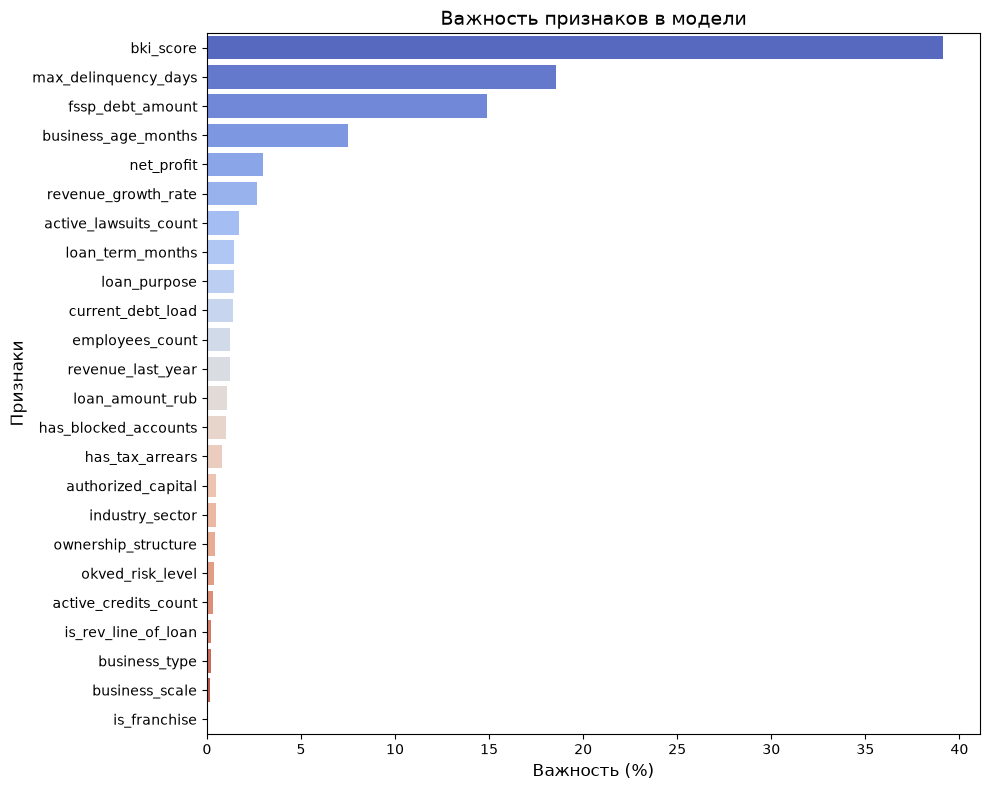

In [9]:
plt.figure(figsize=(10, 8))
sns.barplot(x='importance', y='feature', data=fi_df, palette='coolwarm')
plt.title('Важность признаков в модели', fontsize=14)
plt.xlabel('Важность (%)', fontsize=12)
plt.ylabel('Признаки', fontsize=12)
plt.tight_layout()
plt.show()

Выделенные моделью ключевые качества выглядят разумно: прежде всего она учитывает кредитную оценку заемщика, максимальное количество просроченных дней, сумма задолженностей, возраст бизнеса и чистую прибыль кампании
И меньше всего учитывает такие факторы, как размер и тип бизнеса, сектор экономики и уставной капитал

Метрики качества, получились не идеальные, но хорошие =)

In [13]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

In [14]:
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")

roc_auc = roc_auc_score(y_test, y_pred_proba)
gini = 2 * roc_auc - 1
print(f"ROC-AUC: {roc_auc}")
print(f"Gini: {gini}")

Accuracy:  0.6402
Precision: 0.6350
Recall:    0.6566
F1-Score:  0.6456
ROC-AUC: 0.6876755160365913
Gini: 0.37535103207318254


## 4. Визулизируем модель

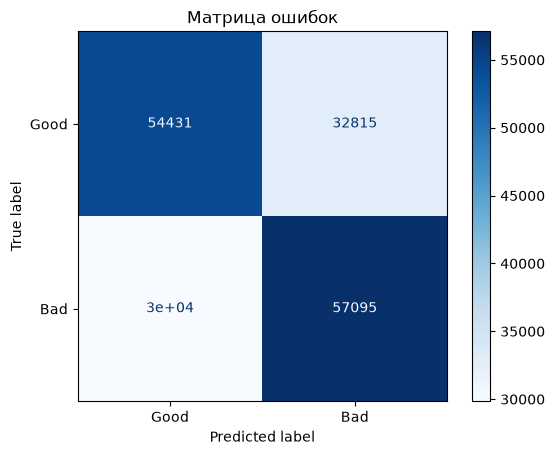

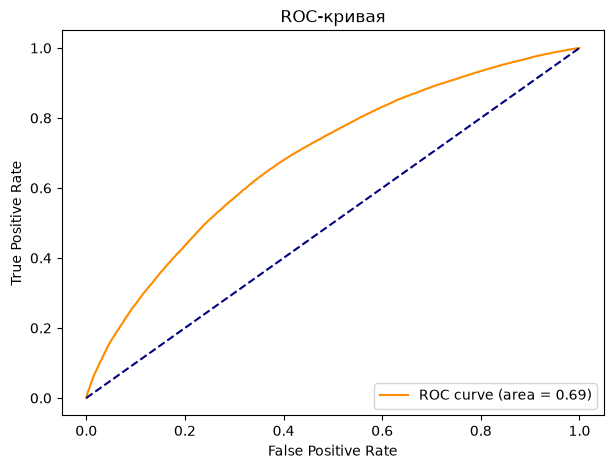

In [16]:
# матрица ошибок
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Good', 'Bad'])
disp.plot(cmap='Blues')
plt.title('Матрица ошибок')
plt.show()

# 2. ROC-кривая
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-кривая')
plt.legend(loc="lower right")
plt.show()

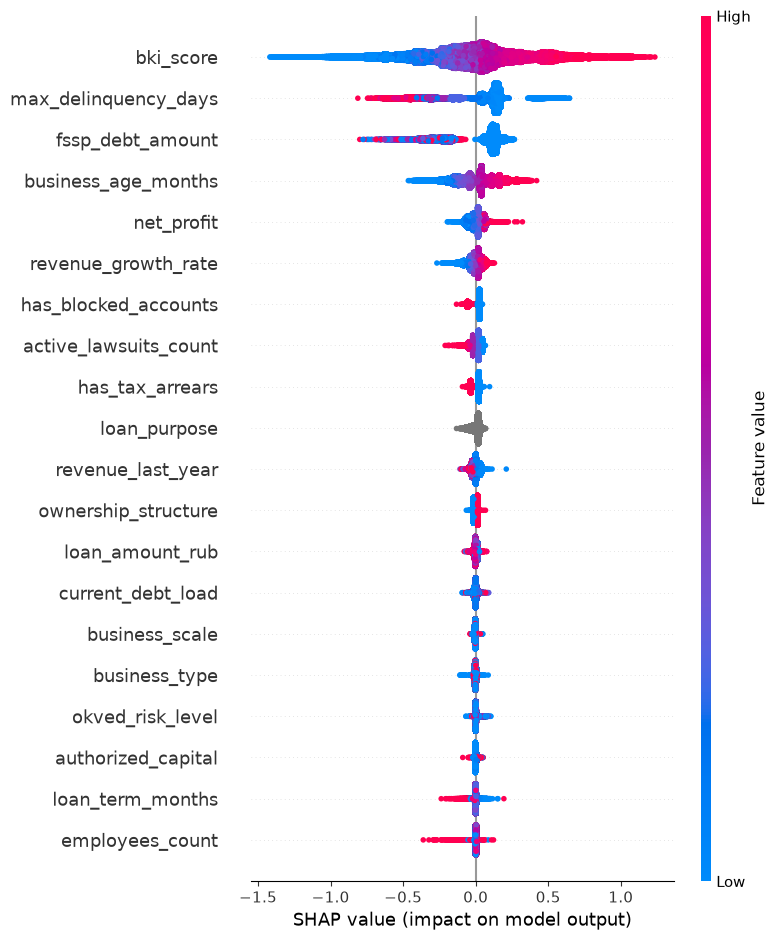

In [ ]:
# инициализируем SHAP эксплейнер для деревьев
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test)

shap.summary_plot(shap_values, X_test)


## 4. Сохраняем модель

In [14]:
model.save_model('../model/model.cbm')